In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

In [3]:
data = pd.read_csv("Womens Clothing E-Commerce Reviews.csv")

In [4]:
data

,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses
3,3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants
4,4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses
...,...,...,...,...,...,...,...,...,...,...,...
23481,23481,1104,34,Great dress for many occasions,I was very happy to snag this dress at such a ...,5,1,0,General Petite,Dresses,Dresses
23482,23482,862,48,Wish it was made of cotton,"It reminds me of maternity clothes. soft, stre...",3,1,0,General Petite,Tops,Knits
23483,23483,1104,31,"Cute, but see through","This fit well, but the top was very see throug...",3,0,1,General Petite,Dresses,Dresses
23484,23484,1084,28,"Very cute dress, perfect for summer parties an...",I bought this dress for a wedding i have this ...,3,1,2,General,Dresses,Dresses


In [5]:
data.shape

(23486, 11)

In [6]:
data.columns

Index(['Unnamed: 0', 'Clothing ID', 'Age', 'Title', 'Review Text', 'Rating',
       'Recommended IND', 'Positive Feedback Count', 'Division Name',
       'Department Name', 'Class Name'],
      dtype='str')

In [7]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 23486 entries, 0 to 23485
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   Unnamed: 0               23486 non-null  int64
 1   Clothing ID              23486 non-null  int64
 2   Age                      23486 non-null  int64
 3   Title                    19676 non-null  str  
 4   Review Text              22641 non-null  str  
 5   Rating                   23486 non-null  int64
 6   Recommended IND          23486 non-null  int64
 7   Positive Feedback Count  23486 non-null  int64
 8   Division Name            23472 non-null  str  
 9   Department Name          23472 non-null  str  
 10  Class Name               23472 non-null  str  
dtypes: int64(6), str(5)
memory usage: 9.5 MB


In [8]:
num_data = data[['Age','Rating','Positive Feedback Count']].copy()

In [9]:
num_data.head()

,Age,Rating,Positive Feedback Count
0,33,4,0
1,34,5,4
2,60,3,0
3,50,5,0
4,47,5,6


In [10]:
num_data.isnull().sum()

Age                        0
Rating                     0
Positive Feedback Count    0
dtype: int64

In [11]:
num_data = num_data.fillna(num_data.median())
num_data = num_data.clip(lower=0)
num_data.head()

,Age,Rating,Positive Feedback Count
0,33,4,0
1,34,5,4
2,60,3,0
3,50,5,0
4,47,5,6


Perform customer behavior clustering

In [12]:
sc = StandardScaler()
scaled_data = sc.fit_transform(num_data)

Apply K-Means clustering

In [13]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

In [14]:
data['Customer_Group'] = kmeans.fit_predict(scaled_data)

In [15]:
data[['Age','Rating','Positive Feedback Count','Customer_Group']].head()

,Age,Rating,Positive Feedback Count,Customer_Group
0,33,4,0,0
1,34,5,4,0
2,60,3,0,2
3,50,5,0,2
4,47,5,6,2


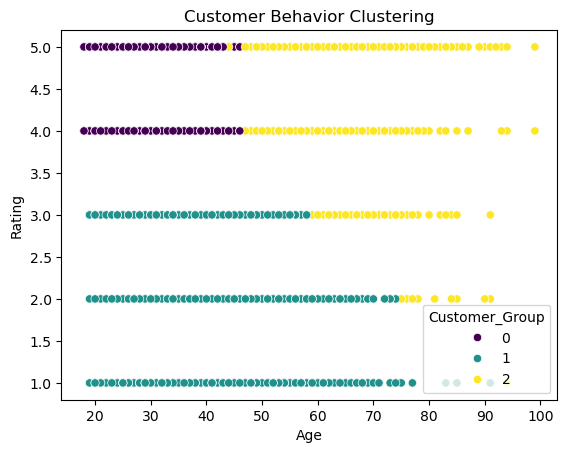

In [16]:
sns.scatterplot(
    data = data,
    x = 'Age',
    y = 'Rating',
    hue = 'Customer_Group',
    palette = 'viridis'
)
plt.title("Customer Behavior Clustering")
plt.show()

Detect multicollinearity

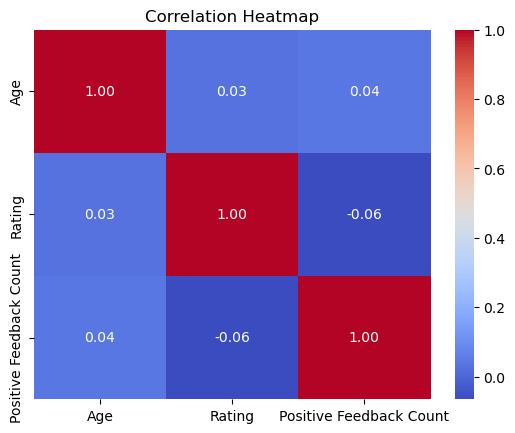

In [17]:
correlation = num_data.corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt = '.2f'
)

plt.title("Correlation Heatmap")
plt.show()

In [18]:
for i in range(len(correlation.columns)):
    for j in range(i):
        value = correlation.iloc[i,j]

        if abs(value) > 0.7:
            print(correlation.columns[i],
                  "and",
                 correlation.columns[j],
                 "=",round(value,2))

In [19]:
for i in range(len(correlation.columns)):
    for j in range(i):
        value = correlation.iloc[i, j]

        if abs(value) > 0.7:
            print(
                correlation.columns[i],
                "and",
                correlation.columns[j],
                "=", round(value, 2)
            )

Build a predictive model

In [20]:
print(data['Recommended IND'].value_counts())

Recommended IND
1    19314
0     4172
Name: count, dtype: int64


In [21]:
x = data[['Age','Rating','Positive Feedback Count']]
y = data[['Recommended IND']]

In [22]:
data2 = data[['Age','Rating','Positive Feedback Count','Recommended IND']].dropna(subset=['Recommended IND'])

In [23]:
x = data2[['Age','Rating','Positive Feedback Count']]
y = data2[['Recommended IND']]

In [24]:
x = x.fillna(x.mean())

In [25]:
x_train,x_test,y_train,y_test = train_test_split(
    x,y,test_size=0.2,random_state=42,stratify=y
)

In [26]:
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)
model.fit(x_train,y_train)

D:\anaconda\Lib\site-packages\sklearn\base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [27]:
y_pred = model.predict(x_test)

In [28]:
accuracy_score(y_test,y_pred)

0.9308216262239251

In [29]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.79      0.84      0.81       835
           1       0.96      0.95      0.96      3863

    accuracy                           0.93      4698
   macro avg       0.88      0.90      0.88      4698
weighted avg       0.93      0.93      0.93      4698



Find the most influential feature

In [30]:
importance = pd.DataFrame({
    'Feature' : x.columns,
    'Importance' : model.feature_importances_
})

In [31]:
importance = importance.sort_values(
    by = 'Importance',
    ascending = False
)

In [32]:
importance

,Feature,Importance
1,Rating,0.878620
0,Age,0.076226
2,Positive Feedback Count,0.045154


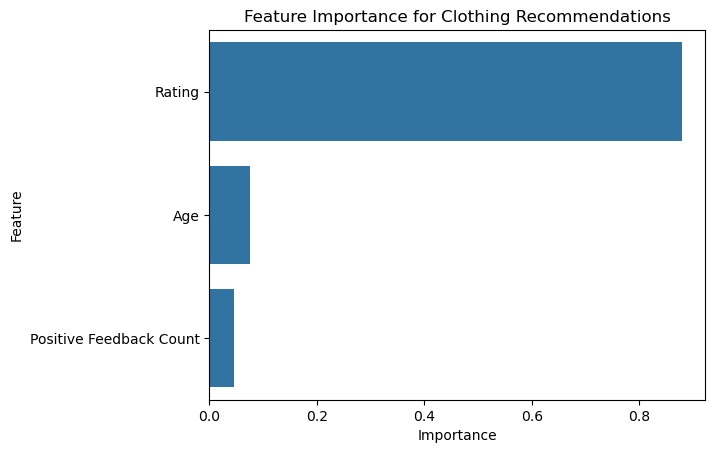

In [33]:
sns.barplot(data=importance,x='Importance',y='Feature')
plt.title("Feature Importance for Clothing Recommendations")
plt.show()